# Milestone 1: Formula 1 Podium Prediction Companion

This is the complete, self-contained Kaggle submission notebook. Every function used for loading, auditing, cleaning, joining, feature engineering, modeling, evaluation, experimentation, explainability, plotting, and inference appears in visible cells below. The notebook does **not** import project code from `pipeline.py`.

The prediction cutoff is after qualifying and before the race starts. The unit of analysis is one driver entering one race, and the binary target is `positionOrder <= 3`. PR-AUC is primary because podiums are rare; ROC-AUC is secondary. F1, precision, and recall are calculated at thresholds selected from validation data only.

## 0. Kaggle setup

Attach the public **Formula 1 World Championship (1950-2024)** Kaggle dataset containing the 14 CSV files, then choose **Run All**. No source ZIP or repository module is needed. The raw CSV files are read only and never modified.

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

def locate_data() -> Path:
    '''Find the raw CSV directory locally or in Kaggle's attached inputs.'''
    # Use the repository data locally. On Kaggle, find the folder containing
    # results.csv instead of relying on the generated dataset path.
    local = ROOT / "data" / "raw"
    if (local / "results.csv").exists():
        return local
    kaggle_root = Path("/kaggle/input")
    matches = sorted(kaggle_root.rglob("results.csv")) if kaggle_root.exists() else []
    if not matches:
        raise FileNotFoundError("Attach the Formula 1 dataset containing results.csv.")
    return matches[0].parent

DATA = locate_data()
OUT = Path("/kaggle/working/artifacts") if Path("/kaggle/working").exists() else ROOT / "artifacts"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Raw data: {DATA}")
print(f"Generated artifacts: {OUT}")

Raw data: C:\D-\semester-9\ACL-903\ACL-Project\ACL-9th-Paladin\data\raw
Generated artifacts: C:\D-\semester-9\ACL-903\ACL-Project\ACL-9th-Paladin\artifacts


## 1. Imports, analytical contract, and relational schema

The constants define the features, primary keys, and foreign-key relationships used throughout the analysis.

In [2]:
from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SENTINEL = "\\N"

FEATURE_GROUPS = {
    "grid": ["grid_position", "pit_lane_start", "front_row", "field_size"],
    "qualifying": ["qualifying_position", "qualifying_time_seconds", "qualifying_missing"],
    "form": ["driver_podium_rate_5", "constructor_podium_rate_5", "driver_races_before"],
    "standings": ["driver_points_before", "driver_rank_before", "constructor_points_before", "constructor_rank_before"],
    "context": ["driver_age", "round", "year"],
}
FEATURES = [feature for group in FEATURE_GROUPS.values() for feature in group]

PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "races": ["raceId"], "results": ["resultId"],
    "qualifying": ["qualifyId"], "seasons": ["year"], "status": ["statusId"],
}

FOREIGN_KEYS = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "raceId", "races", "raceId"),
]

## 2. Loading, auditing, cleaning, and feature engineering

Literal `\N` values become missing values. Dates and qualifying durations receive semantic types. Shared-drive duplicates are resolved deterministically before leakage-safe historical features are constructed.

In [3]:
def load_raw_tables(data_dir: str | Path) -> dict[str, pd.DataFrame]:
    """Load the supplied CSV files and treat the literal ``\\N`` as missing."""
    data_dir = Path(data_dir)
    tables = {}
    for path in sorted(data_dir.glob("*.csv")):
        tables[path.stem] = pd.read_csv(path, na_values=[SENTINEL], low_memory=False)
    # Fail early here instead of getting a harder-to-read merge error later.
    required = set(PRIMARY_KEYS) | {"sprint_results", "lap_times", "pit_stops"}
    missing = required - tables.keys()
    if missing:
        raise FileNotFoundError(f"Missing required tables: {sorted(missing)}")
    return tables


def audit_tables(tables: dict[str, pd.DataFrame]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Check declared keys and return separate primary-key and foreign-key tables."""
    pk_rows = []
    for table, cols in PRIMARY_KEYS.items():
        frame = tables[table]
        pk_rows.append({"table": table, "key": "+".join(cols),
                        "rows": len(frame), "null_keys": int(frame[cols].isna().any(axis=1).sum()),
                        "duplicate_keys": int(frame.duplicated(cols).sum())})
    fk_rows = []
    for child, col, parent, parent_col in FOREIGN_KEYS:
        values = tables[child][col].dropna()
        # Any child value missing from the parent table is an orphaned reference.
        orphan = ~values.isin(tables[parent][parent_col].dropna())
        fk_rows.append({"relationship": f"{child}.{col} -> {parent}.{parent_col}",
                        "checked": len(values), "orphans": int(orphan.sum())})
    return pd.DataFrame(pk_rows), pd.DataFrame(fk_rows)


def _time_to_seconds(value: Any) -> float:
    """Convert a qualifying time such as ``1:23.456`` to seconds."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    # Minutes are optional because some files store short times as plain seconds.
    match = re.fullmatch(r"(?:(\d+):)?(\d+(?:\.\d+)?)", text)
    if not match:
        return np.nan
    minutes = int(match.group(1) or 0)
    return minutes * 60 + float(match.group(2))


def clean_results(results: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Resolve shared-drive duplicates deterministically.

    We retain the car the driver actually started (grid > 0), then the best final
    classification, then the smallest resultId. This is reproducible and preserves
    the pre-race identity of the entrant whenever possible.
    """
    # Keep the downloaded table unchanged so the audit can still use the raw rows.
    frame = results.copy()
    frame["_started"] = frame["grid"].fillna(0).gt(0)
    counts = frame.groupby(["raceId", "driverId"]).size().rename("rows").reset_index()
    duplicates = counts[counts["rows"] > 1].copy()
    frame = frame.sort_values(
        ["raceId", "driverId", "_started", "positionOrder", "resultId"],
        ascending=[True, True, False, True, True], na_position="last",
    )
    # The sort puts the preferred row first within each driver-race group.
    clean = frame.drop_duplicates(["raceId", "driverId"], keep="first").drop(columns="_started")
    assert not clean.duplicated(["raceId", "driverId"]).any()
    return clean, duplicates


def _previous_standings(standings: pd.DataFrame, races: pd.DataFrame, entity: str) -> pd.DataFrame:
    """Move post-race standings forward so they describe the next race's starting state."""
    columns = ["raceId", entity, "points", "position"]
    s = standings[columns].merge(races[["raceId", "year", "round"]], on="raceId", how="left")
    s = s.sort_values([entity, "year", "round"])
    # A standings row is recorded after a race, so attach it to the next round.
    # Using it on the same race would leak the result we are trying to predict.
    s["next_raceId"] = s.groupby([entity, "year"])["raceId"].shift(-1)
    prefix = "driver" if entity == "driverId" else "constructor"
    return s.dropna(subset=["next_raceId"])[["next_raceId", entity, "points", "position"]].rename(
        columns={"next_raceId": "raceId", "points": f"{prefix}_points_before", "position": f"{prefix}_rank_before"}
    ).assign(raceId=lambda x: x.raceId.astype(int))


def build_modeling_table(tables: dict[str, pd.DataFrame]) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Build one pre-race feature row per driver and return cleaning diagnostics."""
    races = tables["races"].copy()
    races["date"] = pd.to_datetime(races["date"], errors="coerce")
    results, duplicate_groups = clean_results(tables["results"])

    # Start from cleaned race results, then add the entities needed for features
    # and the three analysis questions.
    base = results.merge(races[["raceId", "year", "round", "date", "circuitId", "name"]], on="raceId", validate="many_to_one")
    base = base[base["year"].between(1950, 2024)].copy()
    base = base.merge(tables["drivers"][["driverId", "dob", "nationality"]].rename(columns={"nationality": "driver_nationality"}), on="driverId", validate="many_to_one")
    base = base.merge(tables["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"}), on="constructorId", validate="many_to_one")
    base = base.merge(tables["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"}), on="circuitId", validate="many_to_one")
    base["dob"] = pd.to_datetime(base["dob"], errors="coerce")
    base["driver_age"] = (base["date"] - base["dob"]).dt.days / 365.2425
    base["podium"] = base["positionOrder"].le(3).astype(int)
    # Grid 0 means a pit-lane or exceptional start. Store it separately so zero is
    # not treated as a position ahead of pole.
    base["grid_position"] = base["grid"].where(base["grid"].gt(0))
    base["pit_lane_start"] = base["grid"].eq(0).astype(int)
    base["front_row"] = base["grid"].isin([1, 2]).astype(int)
    base["field_size"] = base.groupby("raceId")["driverId"].transform("size")

    qualifying = tables["qualifying"].copy()
    # Use the driver's best recorded session time. Older races often have no
    # qualifying row, so missingness is kept as its own feature.
    for col in ["q1", "q2", "q3"]:
        qualifying[col + "_seconds"] = qualifying[col].map(_time_to_seconds)
    qualifying["qualifying_time_seconds"] = qualifying[["q1_seconds", "q2_seconds", "q3_seconds"]].min(axis=1)
    qualifying = qualifying.sort_values(["raceId", "driverId", "position", "qualifyId"]).drop_duplicates(["raceId", "driverId"])
    base = base.merge(qualifying[["raceId", "driverId", "position", "qualifying_time_seconds"]].rename(columns={"position": "qualifying_position"}), on=["raceId", "driverId"], how="left", validate="one_to_one")
    base["qualifying_missing"] = base["qualifying_position"].isna().astype(int)

    dprev = _previous_standings(tables["driver_standings"], races, "driverId")
    cprev = _previous_standings(tables["constructor_standings"], races, "constructorId")
    base = base.merge(dprev, on=["raceId", "driverId"], how="left", validate="one_to_one")
    base = base.merge(cprev, on=["raceId", "constructorId"], how="left", validate="many_to_one")

    base = base.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
    # Shift before rolling so a driver's current result cannot enter its own feature.
    base["driver_podium_rate_5"] = base.groupby("driverId")["podium"].transform(lambda s: s.shift().rolling(5, min_periods=1).mean())
    # Aggregate both cars at race level before shifting. A row-level shift could let
    # one teammate see the other teammate's result from the same race.
    constructor_races = (base.groupby(["constructorId", "raceId", "date"], as_index=False)
                         .podium.mean().sort_values(["constructorId", "date", "raceId"]))
    constructor_races["constructor_podium_rate_5"] = constructor_races.groupby("constructorId")["podium"].transform(
        lambda s: s.shift().rolling(5, min_periods=1).mean())
    base = base.merge(constructor_races[["constructorId", "raceId", "constructor_podium_rate_5"]],
                      on=["constructorId", "raceId"], how="left", validate="many_to_one")
    base["driver_races_before"] = base.groupby("driverId").cumcount()

    diagnostics = {
        "raw_result_rows": int(len(tables["results"])),
        "duplicate_driver_race_groups": int(len(duplicate_groups)),
        "clean_rows": int(len(base)),
        "unique_grain": bool(not base.duplicated(["raceId", "driverId"]).any()),
        "year_min": int(base.year.min()), "year_max": int(base.year.max()),
    }
    return base, diagnostics

## 3. EDA, chronological splitting, preprocessing, and models

Training covers 1950-2019, validation 2020-2021, and test 2022-2024. Preprocessing is fitted on training rows only, and all three models use identical rows and features.

In [4]:
def split_by_time(frame: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Create fixed chronological train, validation, and test periods."""
    return {
        "train": frame[frame.year <= 2019].copy(),
        "validation": frame[frame.year.between(2020, 2021)].copy(),
        "test": frame[frame.year >= 2022].copy(),
    }


def cleaning_eda(raw_results: pd.DataFrame, cleaned: pd.DataFrame) -> pd.DataFrame:
    """Compare row counts and key rates before and after duplicate cleaning."""
    raw = raw_results.copy()
    stages = [("Raw results", raw), ("Cleaned modeling table", cleaned)]
    rows = []
    for stage, data in stages:
        podium = data["positionOrder"].le(3)
        rows.append({
            "stage": stage,
            "rows": int(len(data)),
            "unique_driver_races": int(data[["raceId", "driverId"]].drop_duplicates().shape[0]),
            "duplicate_rows": int(data.duplicated(["raceId", "driverId"], keep=False).sum()),
            "podium_rate": float(podium.mean()),
            "pit_lane_share": float(data["grid"].eq(0).mean()),
            "missing_finish_share": float(data["positionOrder"].isna().mean()),
            "median_grid": float(data.loc[data["grid"].gt(0), "grid"].median()),
        })
    return pd.DataFrame(rows)


def _pipeline(model: Any, scale: bool = True, strategy: str = "median") -> Pipeline:
    """Wrap a model with imputation and optional scaling fitted on training data."""
    steps = [("imputer", SimpleImputer(strategy=strategy, fill_value=0))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline([("preprocess", Pipeline(steps)), ("model", model)])


def model_definitions(random_state: int = 42) -> dict[str, Pipeline]:
    """Return the three candidate models with reproducible settings."""
    return {
        "Logistic regression": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=random_state)),
        "Random forest": _pipeline(RandomForestClassifier(n_estimators=240, min_samples_leaf=4, class_weight="balanced_subsample", n_jobs=1, random_state=random_state), scale=False),
        "Shallow neural network": _pipeline(MLPClassifier(hidden_layer_sizes=(32, 12), alpha=0.002, early_stopping=True, max_iter=300, random_state=random_state)),
    }


def _best_threshold(y: pd.Series, probability: np.ndarray) -> float:
    """Choose the validation threshold with the highest F1 score."""
    candidates = np.linspace(0.05, 0.80, 151)
    # Threshold selection uses validation predictions only. The test set stays out.
    scores = [f1_score(y, probability >= value, zero_division=0) for value in candidates]
    return float(candidates[int(np.argmax(scores))])


def _metrics(y: pd.Series, probability: np.ndarray, threshold: float) -> dict[str, float]:
    """Calculate ranking metrics and threshold-based classification metrics."""
    prediction = probability >= threshold
    return {
        "ROC-AUC": float(roc_auc_score(y, probability)),
        "PR-AUC": float(average_precision_score(y, probability)),
        "F1": float(f1_score(y, prediction, zero_division=0)),
        "Precision": float(precision_score(y, prediction, zero_division=0)),
        "Recall": float(recall_score(y, prediction, zero_division=0)),
    }


def train_and_evaluate(frame: pd.DataFrame, random_state: int = 42) -> tuple[dict[str, Pipeline], pd.DataFrame, dict[str, float]]:
    """Fit each candidate on training years and score every chronological split."""
    splits = split_by_time(frame)
    trained, rows, thresholds = {}, [], {}
    for name, model in model_definitions(random_state).items():
        model.fit(splits["train"][FEATURES], splits["train"]["podium"])
        # Each model gets its own cutoff because their probability scales differ.
        val_probability = model.predict_proba(splits["validation"][FEATURES])[:, 1]
        threshold = _best_threshold(splits["validation"]["podium"], val_probability)
        thresholds[name] = threshold
        trained[name] = model
        for split_name, split in splits.items():
            probability = model.predict_proba(split[FEATURES])[:, 1]
            rows.append({"model": name, "split": split_name, "threshold": threshold,
                         **_metrics(split["podium"], probability, threshold)})
    return trained, pd.DataFrame(rows), thresholds


def preprocessing_experiments(frame: pd.DataFrame) -> pd.DataFrame:
    """Compare imputation and scaling choices using validation scores only."""
    splits = split_by_time(frame)
    variants = {
        "median + scaling": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42), True, "median"),
        "median, no scaling": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42), False, "median"),
        "zero + scaling": _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42), True, "constant"),
    }
    rows = []
    for name, model in variants.items():
        model.fit(splits["train"][FEATURES], splits["train"].podium)
        p = model.predict_proba(splits["validation"][FEATURES])[:, 1]
        rows.append({"preprocessing": name, "validation_ROC-AUC": roc_auc_score(splits["validation"].podium, p),
                     "validation_PR-AUC": average_precision_score(splits["validation"].podium, p)})
    return pd.DataFrame(rows)


def ablation_experiments(frame: pd.DataFrame) -> pd.DataFrame:
    """Remove one feature group at a time and measure the validation score change."""
    splits = split_by_time(frame)
    rows = []
    variants = {"all features": FEATURES}
    variants.update({f"without {group}": [f for f in FEATURES if f not in columns] for group, columns in FEATURE_GROUPS.items()})
    for name, features in variants.items():
        model = _pipeline(LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42))
        model.fit(splits["train"][features], splits["train"].podium)
        p = model.predict_proba(splits["validation"][features])[:, 1]
        rows.append({"variant": name, "features": len(features), "validation_PR-AUC": average_precision_score(splits["validation"].podium, p),
                     "validation_ROC-AUC": roc_auc_score(splits["validation"].podium, p)})
    result = pd.DataFrame(rows)
    # Negative changes mean the removed group was helping the full model.
    baseline = result.loc[result.variant.eq("all features"), "validation_PR-AUC"].iloc[0]
    result["PR-AUC_change"] = result["validation_PR-AUC"] - baseline
    return result

## 4. Data-engineering questions

These functions answer the three required multi-hop relational questions and document the status and nationality mappings used by them.

In [5]:
MECHANICAL_TERMS = {
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Suspension",
    "Brakes", "Differential", "Overheating", "Mechanical", "Tyre", "Puncture", "Driveshaft",
    "Radiator", "Oil pressure", "Water leak", "Fuel pump", "Power Unit", "Turbo", "ERS",
    "Water pressure", "Oil leak", "Fuel pressure", "Wheel bearing", "Throttle", "Steering",
    "Technical", "Electronics", "Battery", "Alternator", "Spark plugs", "Fuel system",
    "Power loss", "Wheel", "Exhaust", "Undertray", "Wheel nut", "Front wing", "Rear wing",
    "Fuel leak", "Vibrations", "Drivetrain", "Brake duct", "Cooling system", "Water pump",
}

# Exclude recorded non-starters from the mechanical-failure denominator.
NON_START_STATUSES = {"Withdrew", "Did not start", "Did not qualify", "Did not prequalify", "Excluded"}

NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria",
    "Belgian": "Belgium", "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chinese": "China", "Dutch": "Netherlands", "Finnish": "Finland", "French": "France",
    "German": "Germany", "Hungarian": "Hungary", "Indian": "India", "Italian": "Italy",
    "Japanese": "Japan", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Portuguese": "Portugal", "Russian": "Russia",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
}


def engineering_answers(frame: pd.DataFrame, tables: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:
    """Build the result tables for the three required data-engineering questions."""
    # Use the final grid for the front-row question because penalties can change a
    # driver's position between qualifying and the actual start.
    q1_source = frame[frame.grid.isin([1, 2])].copy()
    q1_source["era"] = np.where(q1_source.year >= 2014, "2014-2024", "1950-2013")
    q1 = (q1_source.groupby(["era", "circuit_name"]).podium.agg(["mean", "count"]).reset_index()
          .query("count >= 10").sort_values(["era", "mean"], ascending=[True, False]))

    # Compare home and away drivers within broad grid bands. This does not make the
    # result causal, but it avoids comparing front-row and back-row starts directly.
    home = frame.copy()
    home["home_country"] = home.driver_nationality.map(NATIONALITY_TO_COUNTRY)
    home = home[home.home_country.notna() & home.grid_position.notna()].copy()
    home["home_race"] = home.home_country.eq(home.country)
    home["grid_band"] = pd.cut(home.grid_position, [0, 3, 6, 10, 15, 100], labels=["1-3", "4-6", "7-10", "11-15", "16+"])
    q2 = home.groupby(["grid_band", "home_race"], observed=True).podium.agg(["mean", "count"]).reset_index()

    # Count only the component failures listed above. Ambiguous statuses stay out of
    # the numerator, and recorded non-starters stay out of the denominator.
    status = tables["status"].set_index("statusId")["status"]
    q3_source = frame[frame.year.between(2014, 2024)].copy()
    q3_source["status_text"] = q3_source.statusId.map(status)
    q3_source = q3_source[~q3_source.status_text.isin(NON_START_STATUSES)].copy()
    q3_source["mechanical"] = q3_source.status_text.isin(MECHANICAL_TERMS)
    q3_source["era"] = np.where(q3_source.year <= 2021, "2014-2021", "2022-2024")
    q3 = q3_source.groupby(["era", "constructor_name"]).mechanical.agg(["mean", "sum", "count"]).reset_index()
    q3 = q3[q3["count"] >= 20].sort_values(["era", "mean"], ascending=[True, False])
    return {"front_row_circuits": q1, "home_effect": q2, "mechanical_retirements": q3}

## 5. Visual evidence and explainability

The figures cover cleaning, missingness, all analytical questions, model comparison, ablation, permutation importance, global SHAP, local LIME, and a local SHAP cross-check.

In [6]:
def create_plots(frame: pd.DataFrame, cleaning: pd.DataFrame,
                 answers: dict[str, pd.DataFrame], metrics: pd.DataFrame,
                 ablations: pd.DataFrame, trained: dict[str, Pipeline], out_dir: str | Path) -> dict[str, str]:
    """Create the report figures and return their output paths."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid", context="notebook")
    paths = {}
    def save(name: str):
        """Apply the shared layout, save the active figure, and close it."""
        path = out / f"{name}.png"; plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight"); plt.close(); paths[name] = str(path)

    # Show whether duplicate removal changed the grain or important outcome rates.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    counts = cleaning.melt(id_vars="stage", value_vars=["rows", "unique_driver_races"],
                           var_name="measure", value_name="count")
    sns.barplot(counts, x="stage", y="count", hue="measure", ax=axes[0])
    axes[0].set_title("Grain before and after cleaning")
    axes[0].set_xlabel(""); axes[0].set_ylabel("Rows / unique pairs")
    axes[0].tick_params(axis="x", rotation=10)
    rates = cleaning.melt(id_vars="stage", value_vars=["podium_rate", "pit_lane_share", "missing_finish_share"],
                          var_name="measure", value_name="share")
    sns.barplot(rates, x="measure", y="share", hue="stage", ax=axes[1])
    axes[1].set_title("Rates affected by row selection")
    axes[1].set_xlabel(""); axes[1].set_ylabel("Share of rows")
    axes[1].tick_params(axis="x", rotation=15)
    fig.tight_layout(); fig.savefig(out / "cleaning_before_after.png", dpi=150, bbox_inches="tight"); plt.close(fig)
    paths["cleaning_before_after"] = str(out / "cleaning_before_after.png")

    coverage = frame.groupby("year").qualifying_position.apply(lambda x: x.notna().mean()).reset_index(name="coverage")
    plt.figure(figsize=(10, 4)); sns.lineplot(coverage, x="year", y="coverage"); plt.ylabel("Qualifying coverage"); plt.title("Qualifying coverage by season"); save("qualifying_coverage")

    q1 = answers["front_row_circuits"].groupby("era").head(10)
    plt.figure(figsize=(10, 6)); sns.barplot(q1, y="circuit_name", x="mean", hue="era"); plt.xlabel("Front-row to podium rate"); plt.ylabel(""); save("front_row_conversion")

    q2 = answers["home_effect"]
    plt.figure(figsize=(8, 4)); sns.lineplot(q2, x="grid_band", y="mean", hue="home_race", marker="o"); plt.ylabel("Podium rate"); plt.xlabel("Starting-grid band"); save("home_effect")

    q3 = answers["mechanical_retirements"].groupby("era").head(10)
    plt.figure(figsize=(10, 6)); sns.barplot(q3, y="constructor_name", x="mean", hue="era"); plt.xlabel("Mechanical-retirement rate"); plt.ylabel(""); save("mechanical_retirements")

    test_metrics = metrics[metrics.split.eq("test")].melt(id_vars=["model", "split", "threshold"], value_vars=["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"], var_name="metric", value_name="score")
    plt.figure(figsize=(10, 5)); sns.barplot(test_metrics, x="metric", y="score", hue="model"); plt.ylim(0, 1); save("model_comparison")

    plt.figure(figsize=(9, 4)); sns.barplot(ablations, y="variant", x="PR-AUC_change"); plt.axvline(0, color="black", lw=1); save("ablation")

    # Use a fixed validation sample to keep repeated permutation scoring manageable.
    split = split_by_time(frame); forest = trained["Random forest"]
    sample = split["validation"].sample(min(1000, len(split["validation"])), random_state=42)
    perm = permutation_importance(forest, sample[FEATURES], sample.podium, scoring="average_precision", n_repeats=5, random_state=42, n_jobs=1)
    importance = pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean}).sort_values("importance", ascending=False)
    plt.figure(figsize=(9, 6)); sns.barplot(importance.head(12), y="feature", x="importance"); save("permutation_importance")
    importance.to_csv(out / "permutation_importance.csv", index=False)
    return paths


def shap_explanations(frame: pd.DataFrame, trained: dict[str, Pipeline], out_dir: str | Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Create global and single-row SHAP explanations for the random forest."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    try:
        import shap
    except ImportError:
        # Some managed Windows setups block Numba's compiled extension. Reuse saved
        # SHAP results there; Kaggle and normal environments calculate them directly.
        global_csv, local_csv = out / "shap_global.csv", out / "shap_local.csv"
        if global_csv.exists() and local_csv.exists():
            return pd.read_csv(global_csv), pd.read_csv(local_csv)
        raise
    split = split_by_time(frame)
    # A fixed sample keeps the plot reproducible without explaining every row.
    sample = split["validation"].sample(min(400, len(split["validation"])), random_state=42)
    forest = trained["Random forest"]
    X = forest.named_steps["preprocess"].transform(sample[FEATURES])
    explainer = shap.TreeExplainer(forest.named_steps["model"])
    values = explainer.shap_values(X)
    # SHAP has used both list and 3D-array outputs across versions. We only need the
    # contributions for the podium class.
    if isinstance(values, list):
        values = values[1]
    elif values.ndim == 3:
        values = values[:, :, 1]
    global_df = pd.DataFrame({"feature": FEATURES, "mean_abs_shap": np.abs(values).mean(axis=0)}).sort_values("mean_abs_shap", ascending=False)
    plt.figure(figsize=(9, 6)); sns.barplot(global_df.head(12), y="feature", x="mean_abs_shap"); plt.tight_layout(); plt.savefig(out / "shap_global.png", dpi=150, bbox_inches="tight"); plt.close()
    row_values = values[0]
    local_df = pd.DataFrame({"feature": FEATURES, "shap_value": row_values, "observed_value": sample.iloc[0][FEATURES].values}).sort_values("shap_value", key=np.abs, ascending=False)
    plt.figure(figsize=(9, 6)); sns.barplot(local_df.head(12), y="feature", x="shap_value"); plt.axvline(0, color="black", lw=1); plt.tight_layout(); plt.savefig(out / "shap_local.png", dpi=150, bbox_inches="tight"); plt.close()
    global_df.to_csv(out / "shap_global.csv", index=False); local_df.to_csv(out / "shap_local.csv", index=False)
    return global_df, local_df


def lime_explanation(frame: pd.DataFrame, trained: dict[str, Pipeline], out_dir: str | Path,
                     n_samples: int = 5000) -> pd.DataFrame:
    """Explain one validation prediction with a small local LIME surrogate.

    Each synthetic row keeps some values from the explained case and replaces the
    rest with values from training rows. ``n_samples`` controls the local sample size.
    The returned table includes signed feature weights and a fidelity score.
    """
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    split = split_by_time(frame)
    train = split["train"][FEATURES].reset_index(drop=True)
    explained = split["validation"].sample(1, random_state=42).iloc[0]
    model = trained["Random forest"]
    rng = np.random.default_rng(42)

    # Draw replacements from training data so the test period cannot affect LIME.
    background = train.iloc[rng.integers(0, len(train), size=n_samples)].reset_index(drop=True)
    # A 1 keeps the explained value. Keeping most values makes these synthetic rows
    # local rather than unrelated points drawn across the full data set.
    interpretable = rng.binomial(1, 0.8, size=(n_samples, len(FEATURES))).astype(float)
    # Include the exact row so the surrogate is anchored at the shown prediction.
    interpretable[0, :] = 1.0
    perturbed = background.copy()
    for j, feature in enumerate(FEATURES):
        perturbed.loc[interpretable[:, j].astype(bool), feature] = explained[feature]

    # Fit a simple model to the forest's local predictions. Rows with more replaced
    # values get less weight because they are farther from the case being explained.
    probabilities = model.predict_proba(perturbed)[:, 1]
    distances = np.sqrt(((1.0 - interpretable) ** 2).sum(axis=1))
    kernel_width = 0.75 * np.sqrt(len(FEATURES))
    weights = np.exp(-(distances ** 2) / (kernel_width ** 2))
    surrogate = Ridge(alpha=0.01).fit(interpretable, probabilities, sample_weight=weights)
    local_prediction = float(surrogate.predict(np.ones((1, len(FEATURES))))[0])
    model_prediction = float(model.predict_proba(pd.DataFrame([explained[FEATURES]]))[0, 1])
    # Report weighted R2 so a weak local approximation is visible to the reader.
    fidelity = float(surrogate.score(interpretable, probabilities, sample_weight=weights))

    local_df = pd.DataFrame({
        "feature": FEATURES,
        "lime_weight": surrogate.coef_,
        "observed_value": explained[FEATURES].values,
        "model_probability": model_prediction,
        "surrogate_probability": local_prediction,
        "local_fidelity_r2": fidelity,
    }).sort_values("lime_weight", key=np.abs, ascending=False)
    colors = np.where(local_df.head(12).lime_weight.ge(0), "#2a9d8f", "#e76f51")
    plt.figure(figsize=(9, 6))
    plt.barh(local_df.head(12).feature[::-1], local_df.head(12).lime_weight[::-1], color=colors[::-1])
    plt.axvline(0, color="black", lw=1)
    plt.xlabel("Local LIME contribution toward podium probability")
    plt.title(f"Local LIME explanation (surrogate weighted R² = {fidelity:.3f})")
    plt.tight_layout(); plt.savefig(out / "lime_local.png", dpi=150, bbox_inches="tight"); plt.close()
    local_df.to_csv(out / "lime_local.csv", index=False)
    return local_df

## 6. Inference and end-to-end execution

The inference function accepts complete and partial records. The runner rebuilds every table, experiment, metric, explanation, and figure used below.

In [7]:
def predict_podium(record: dict[str, Any], model: Pipeline, threshold: float) -> dict[str, Any]:
    """Score one pre-race record, leaving omitted fields for the fitted imputer."""
    row = pd.DataFrame([{feature: record.get(feature, np.nan) for feature in FEATURES}])
    probability = float(model.predict_proba(row)[0, 1])
    return {"podium_probability": probability, "predicted_podium": bool(probability >= threshold), "threshold": threshold}


def run_analysis(data_dir: str | Path = "data/raw", out_dir: str | Path = "artifacts") -> dict[str, Any]:
    """Run the full analysis and write the tables and figures used by the deliverables."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    tables = load_raw_tables(data_dir)
    pk, fk = audit_tables(tables)
    frame, diagnostics = build_modeling_table(tables)
    cleaning = cleaning_eda(tables["results"], frame)
    answers = engineering_answers(frame, tables)
    trained, metrics, thresholds = train_and_evaluate(frame)
    preprocessing = preprocessing_experiments(frame)
    ablations = ablation_experiments(frame)
    plots = create_plots(frame, cleaning, answers, metrics, ablations, trained, out / "figures")
    shap_global, shap_local = shap_explanations(frame, trained, out / "figures")
    lime_local = lime_explanation(frame, trained, out / "figures")

    # Save the intermediate evidence so the report can be rebuilt without retraining.
    frame.to_csv(out / "modeling_table.csv", index=False)
    cleaning.to_csv(out / "cleaning_eda.csv", index=False)
    pk.to_csv(out / "primary_key_audit.csv", index=False); fk.to_csv(out / "foreign_key_audit.csv", index=False)
    metrics.to_csv(out / "model_metrics.csv", index=False); preprocessing.to_csv(out / "preprocessing_experiments.csv", index=False)
    ablations.to_csv(out / "ablation_results.csv", index=False)
    for name, answer in answers.items(): answer.to_csv(out / f"{name}.csv", index=False)
    # Check a complete historical row and an intentionally partial input using the
    # model selected on validation PR-AUC.
    complete = frame.loc[frame.year.ge(2022), FEATURES].dropna().iloc[0].to_dict()
    partial = {"grid_position": 3, "pit_lane_start": 0, "front_row": 0, "field_size": 20, "year": 2024, "round": 5}
    best_name = metrics[metrics.split.eq("validation")].sort_values("PR-AUC", ascending=False).iloc[0].model
    demos = {"model": best_name,
             "complete_record": predict_podium(complete, trained[best_name], thresholds[best_name]),
             "partial_record": predict_podium(partial, trained[best_name], thresholds[best_name])}
    summary = {
        "diagnostics": diagnostics,
        "thresholds": thresholds,
        "inference_demos": demos,
        "mechanical_statuses": sorted(MECHANICAL_TERMS),
        "non_start_statuses": sorted(NON_START_STATUSES),
    }
    (out / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return {"tables": tables, "modeling_table": frame, "pk_audit": pk, "fk_audit": fk,
            "answers": answers, "models": trained, "metrics": metrics, "thresholds": thresholds,
            "preprocessing": preprocessing, "ablations": ablations, "cleaning_eda": cleaning, "plots": plots,
            "shap_global": shap_global, "shap_local": shap_local, "lime_local": lime_local,
            "summary": summary}

## 7. Run the complete pipeline

This call rebuilds all evidence from the attached raw data. There are no hidden manual cells and no imported project implementation.

In [8]:
from IPython.display import Image, display

results = run_analysis(DATA, OUT)
display(results["summary"])

{'diagnostics': {'raw_result_rows': 26759,
  'duplicate_driver_race_groups': 85,
  'clean_rows': 26668,
  'unique_grain': True,
  'year_min': 1950,
  'year_max': 2024},
 'thresholds': {'Logistic regression': 0.655,
  'Random forest': 0.635,
  'Shallow neural network': 0.24},
 'inference_demos': {'model': 'Shallow neural network',
  'complete_record': {'podium_probability': 0.08661545099344511,
   'predicted_podium': False,
   'threshold': 0.24},
  'partial_record': {'podium_probability': 0.03189925681062999,
   'predicted_podium': False,
   'threshold': 0.24}},
 'mechanical_statuses': ['Alternator',
  'Battery',
  'Brake duct',
  'Brakes',
  'Clutch',
  'Cooling system',
  'Differential',
  'Driveshaft',
  'Drivetrain',
  'ERS',
  'Electrical',
  'Electronics',
  'Engine',
  'Exhaust',
  'Front wing',
  'Fuel leak',
  'Fuel pressure',
  'Fuel pump',
  'Fuel system',
  'Gearbox',
  'Hydraulics',
  'Mechanical',
  'Oil leak',
  'Oil pressure',
  'Overheating',
  'Power Unit',
  'Power lo

## 8. Audit, cleaning, and before/after EDA

The audit checks key uniqueness, null keys, and orphan references. The cleaning comparison quantifies the modeling grain, duplicate participation, target rate, pit-lane share, missing finishing classifications, and median grid before and after shared-drive resolution.

,table,key,rows,null_keys,duplicate_keys
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,constructor_results,constructorResultsId,12625,0,0
3,constructor_standings,constructorStandingsId,13391,0,0
4,drivers,driverId,861,0,0
5,driver_standings,driverStandingsId,34863,0,0
6,races,raceId,1125,0,0
7,results,resultId,26759,0,0
8,qualifying,qualifyId,10494,0,0
9,seasons,year,75,0,0


,relationship,checked,orphans
0,races.circuitId -> circuits.circuitId,1125,0
1,results.raceId -> races.raceId,26759,0
2,results.driverId -> drivers.driverId,26759,0
3,results.constructorId -> constructors.construc...,26759,0
4,results.statusId -> status.statusId,26759,0
5,qualifying.raceId -> races.raceId,10494,0
6,qualifying.driverId -> drivers.driverId,10494,0
7,driver_standings.raceId -> races.raceId,34863,0
8,constructor_standings.raceId -> races.raceId,13391,0


{'raw_result_rows': 26759,
 'duplicate_driver_race_groups': 85,
 'clean_rows': 26668,
 'unique_grain': True,
 'year_min': 1950,
 'year_max': 2024}

,stage,rows,unique_driver_races,duplicate_rows,podium_rate,pit_lane_share,missing_finish_share,median_grid
0,Raw results,26759,26668,176,0.126948,0.061213,0.0,12.0
1,Cleaned modeling table,26668,26668,0,0.127306,0.061309,0.0,12.0


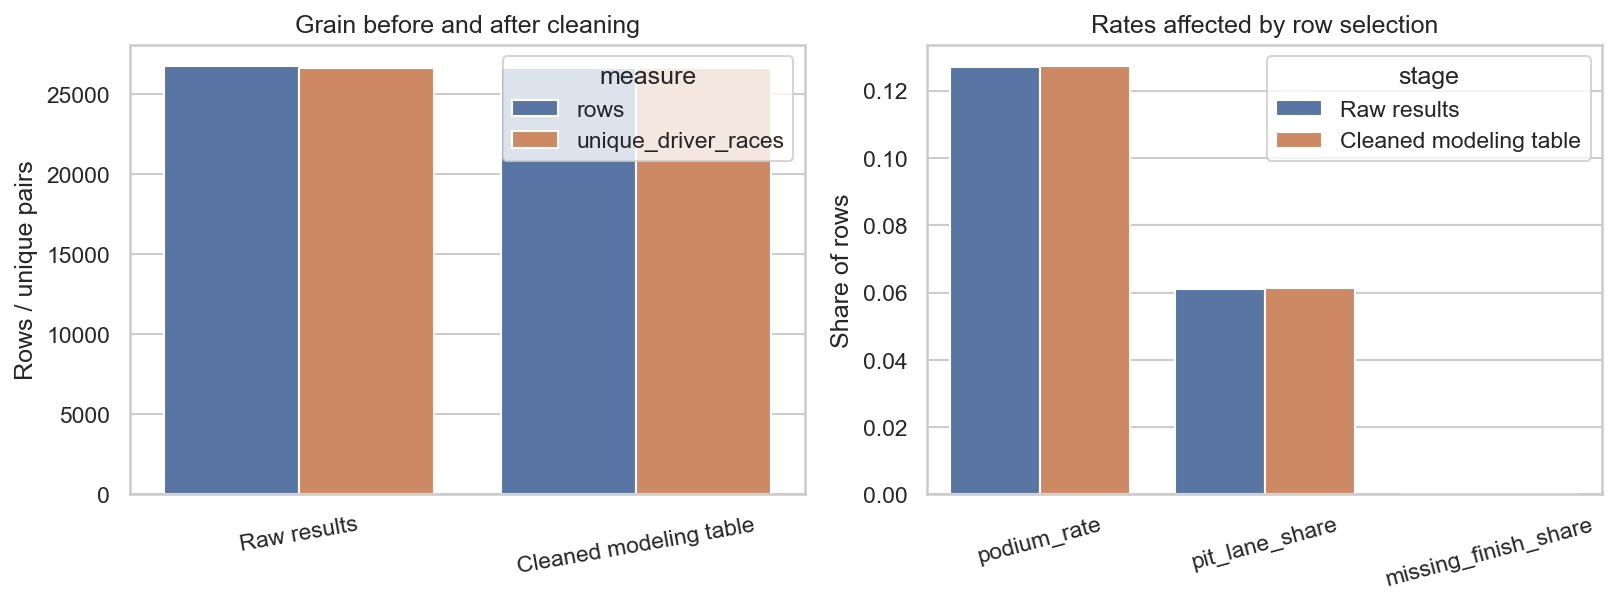

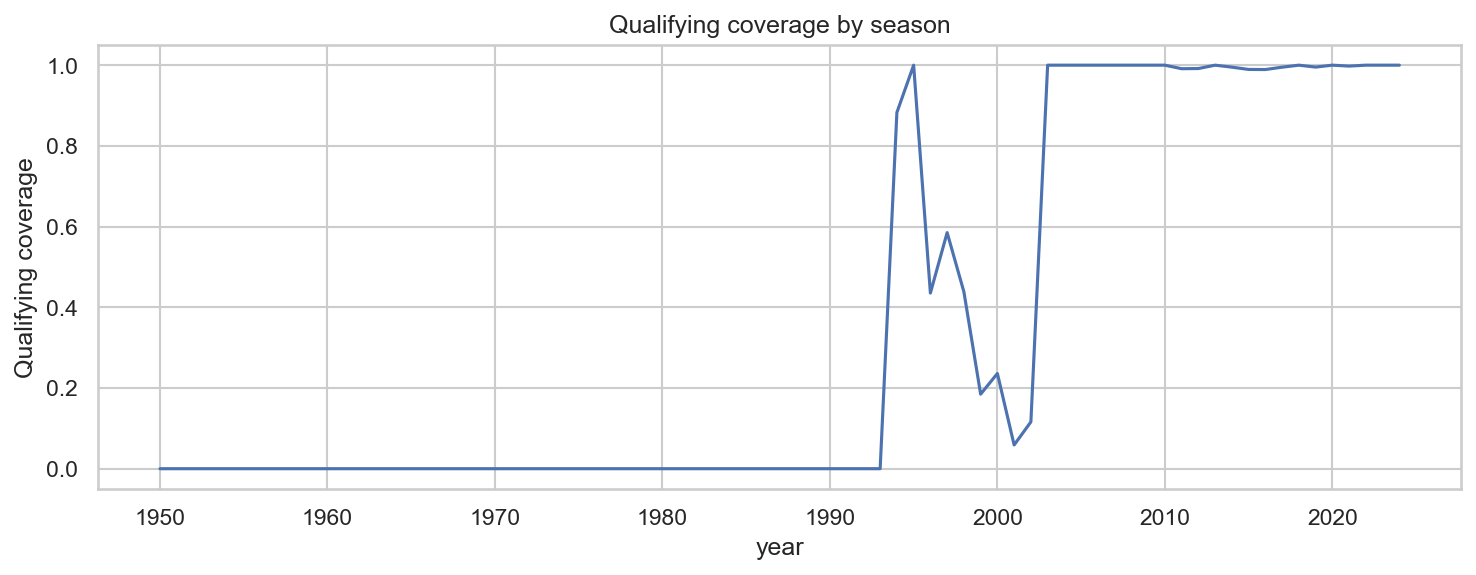

In [9]:
display(results["pk_audit"])
display(results["fk_audit"])
display(results["summary"]["diagnostics"])
display(results["cleaning_eda"])
display(Image(filename=str(OUT / "figures" / "cleaning_before_after.png")))
display(Image(filename=str(OUT / "figures" / "qualifying_coverage.png")))

Cleaning reaches exactly one row per `(raceId, driverId)` without materially changing the target or starting-position distributions. Qualifying coverage is sparse in older seasons, so we retain an explicit missingness flag and use final grid as the historically broader pre-race signal rather than discarding early history.

## 9. Answers to the three data-engineering questions


front_row_circuits


,era,circuit_name,mean,count
23,1950-2013,Circuit de Nevers Magny-Cours,0.805556,36
37,1950-2013,Istanbul Park,0.785714,14
30,1950-2013,Dijon-Prenois,0.750000,12
16,1950-2013,Circuit Bremgarten,0.700000,10
60,1950-2013,Sepang International Circuit,0.700000,30
63,1950-2013,Suzuka Circuit,0.700000,50
35,1950-2013,Hungaroring,0.678571,56
12,1950-2013,Bahrain International Circuit,0.666667,18
11,1950-2013,Autódromo do Estoril,0.653846,26
21,1950-2013,Circuit de Barcelona-Catalunya,0.652174,46



home_effect


,grid_band,home_race,mean,count
0,1-3,False,0.556536,3060
1,1-3,True,0.549242,264
2,4-6,False,0.263263,3016
3,4-6,True,0.246154,260
4,7-10,False,0.095489,3990
5,7-10,True,0.087855,387
6,11-15,False,0.030813,4933
7,11-15,True,0.034115,469
8,16+,False,0.007532,6904
9,16+,True,0.007479,936



mechanical_retirements


,era,constructor_name,mean,sum,count
4,2014-2021,Caterham,0.235294,8,34
8,2014-2021,Lotus F1,0.200000,15,75
17,2014-2021,Toro Rosso,0.165289,40,242
15,2014-2021,Renault,0.145000,29,200
11,2014-2021,McLaren,0.144654,46,318
16,2014-2021,Sauber,0.115000,23,200
14,2014-2021,Red Bull,0.112853,36,319
13,2014-2021,Racing Point,0.105263,8,76
1,2014-2021,AlphaTauri,0.102564,8,78
10,2014-2021,Marussia,0.096774,3,31


Statuses counted as mechanical:


['Alternator',
 'Battery',
 'Brake duct',
 'Brakes',
 'Clutch',
 'Cooling system',
 'Differential',
 'Driveshaft',
 'Drivetrain',
 'ERS',
 'Electrical',
 'Electronics',
 'Engine',
 'Exhaust',
 'Front wing',
 'Fuel leak',
 'Fuel pressure',
 'Fuel pump',
 'Fuel system',
 'Gearbox',
 'Hydraulics',
 'Mechanical',
 'Oil leak',
 'Oil pressure',
 'Overheating',
 'Power Unit',
 'Power loss',
 'Puncture',
 'Radiator',
 'Rear wing',
 'Spark plugs',
 'Steering',
 'Suspension',
 'Technical',
 'Throttle',
 'Transmission',
 'Turbo',
 'Tyre',
 'Undertray',
 'Vibrations',
 'Water leak',
 'Water pressure',
 'Water pump',
 'Wheel',
 'Wheel bearing',
 'Wheel nut']

Statuses excluded as non-starts:


['Did not prequalify',
 'Did not qualify',
 'Did not start',
 'Excluded',
 'Withdrew']

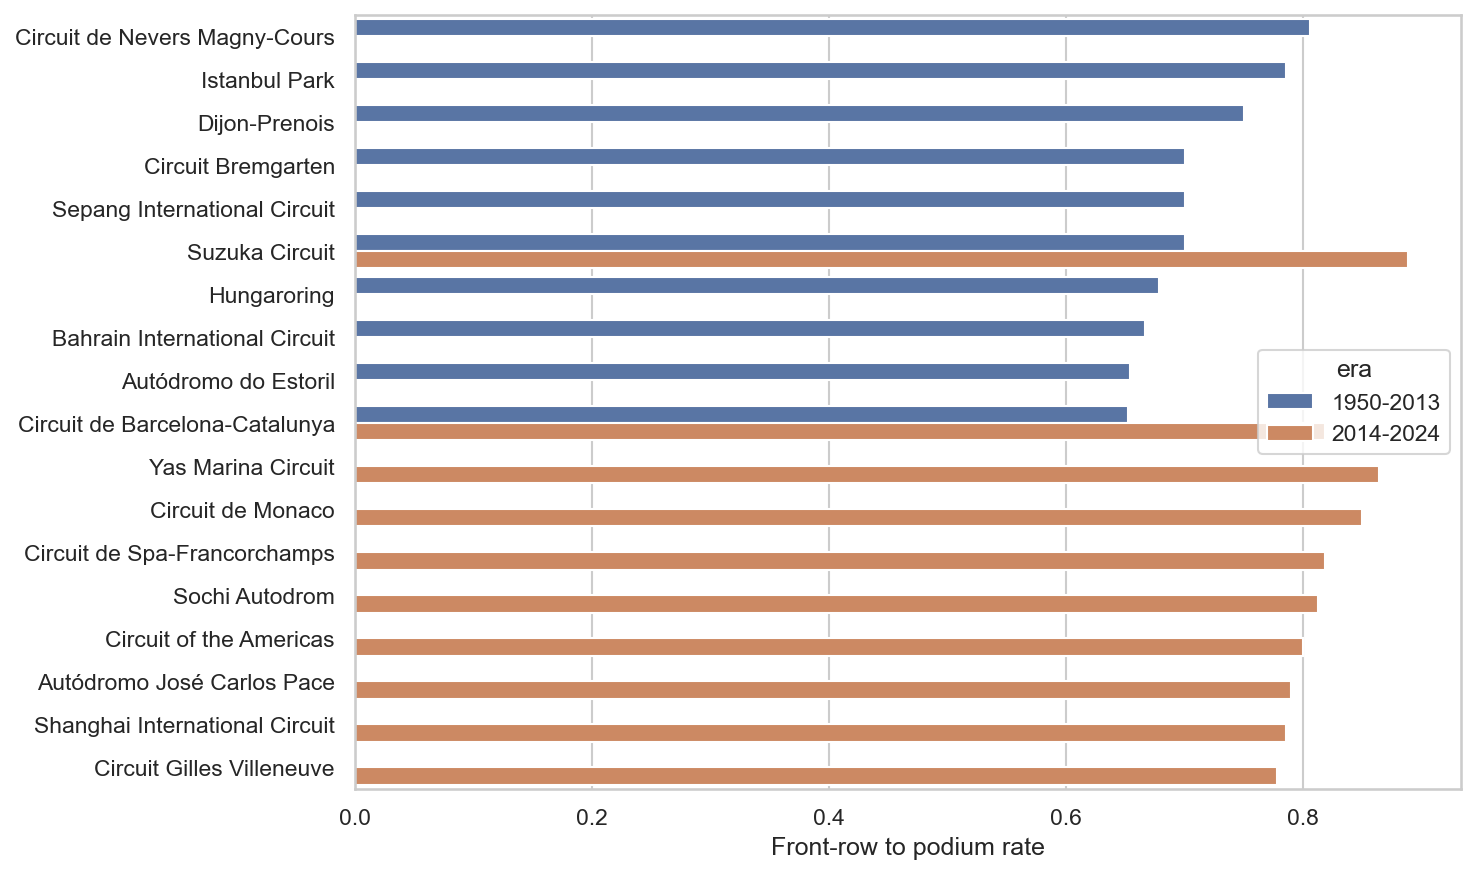

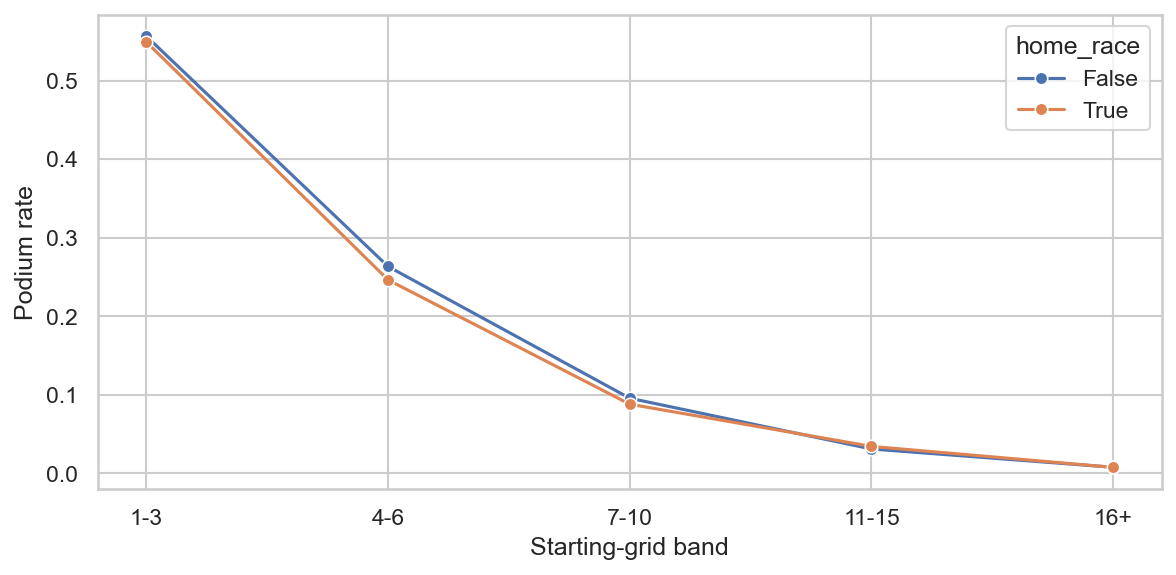

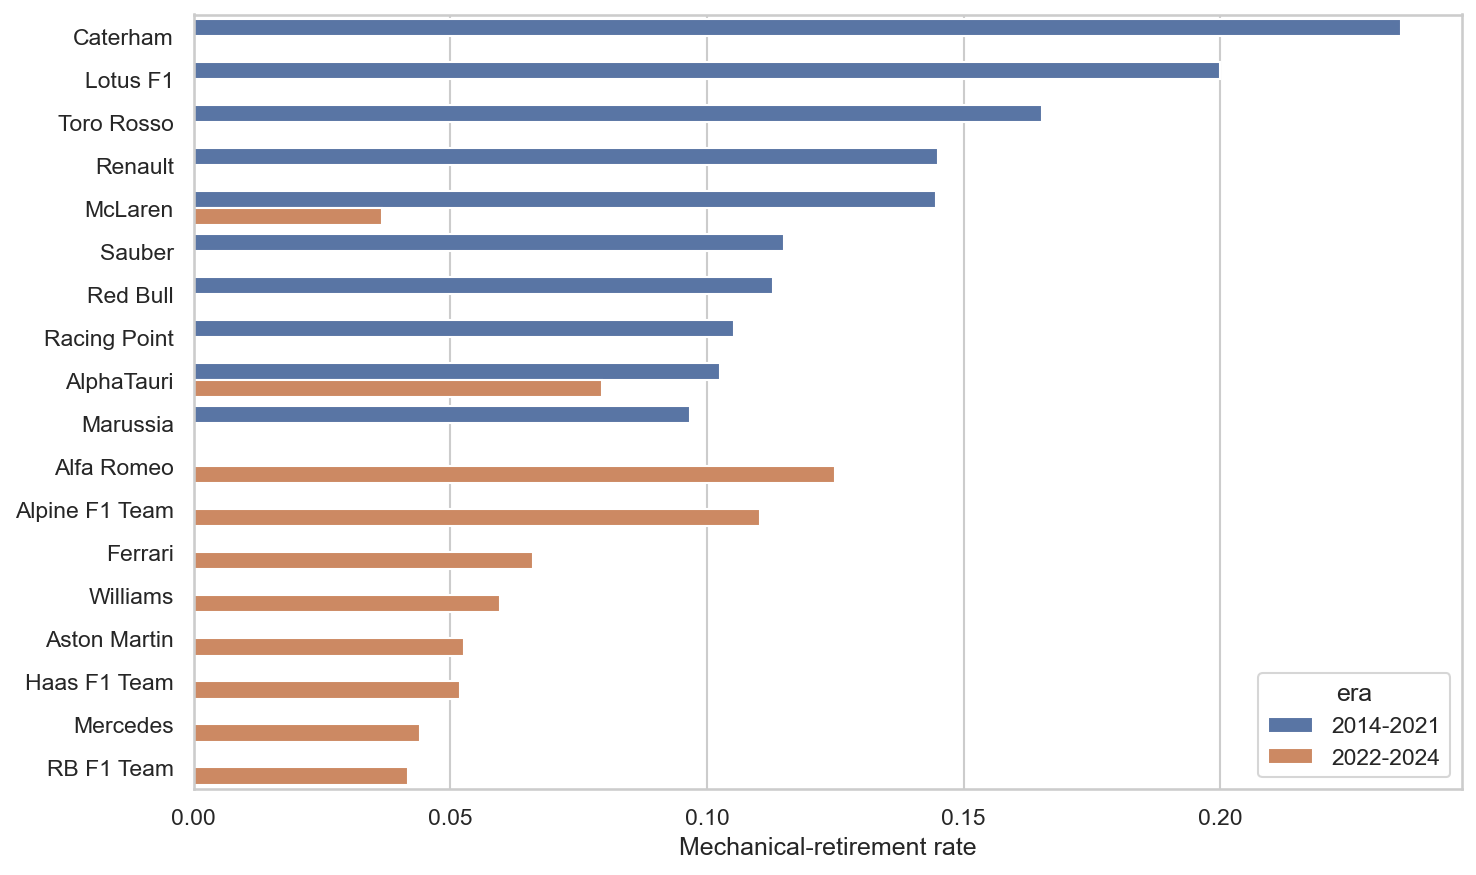

In [10]:
for key, table in results["answers"].items():
    print(f"\n{key}")
    display(table.groupby("era").head(10) if "era" in table else table)

print("Statuses counted as mechanical:")
display(results["summary"]["mechanical_statuses"])
print("Statuses excluded as non-starts:")
display(results["summary"]["non_start_statuses"])

for figure in ["front_row_conversion", "home_effect", "mechanical_retirements"]:
    display(Image(filename=str(OUT / "figures" / f"{figure}.png")))

**Front-row conversion.** Rankings are separated at the 2014 hybrid-era boundary and require at least ten front-row starts per circuit-era. Final grid positions 1-2 define the front row because penalties can make qualifying order differ from the actual start.

**Home-country effect.** Home and away rates are compared inside the same grid bands. This controls the dominant starting-position pattern transparently, but the result remains descriptive rather than causal.

**Mechanical retirements.** Rates use recorded race starters as the denominator and documented component-status labels as the numerator, with at least twenty starts per constructor-era. Ambiguous status coding remains a limitation.

## 10. Leakage-safe features and chronological split

In [11]:
display(FEATURE_GROUPS)
splits = split_by_time(results["modeling_table"])
split_summary = pd.DataFrame([
    {"split": name, "years": f"{int(part.year.min())}-{int(part.year.max())}",
     "rows": len(part), "races": part.raceId.nunique(),
     "podium_rate": part.podium.mean(),
     "qualifying_missing": part.qualifying_missing.mean()}
    for name, part in splits.items()
])
display(split_summary)

{'grid': ['grid_position', 'pit_lane_start', 'front_row', 'field_size'],
 'qualifying': ['qualifying_position',
  'qualifying_time_seconds',
  'qualifying_missing'],
 'form': ['driver_podium_rate_5',
  'constructor_podium_rate_5',
  'driver_races_before'],
 'standings': ['driver_points_before',
  'driver_rank_before',
  'constructor_points_before',
  'constructor_rank_before'],
 'context': ['driver_age', 'round', 'year']}

,split,years,rows,races,podium_rate,qualifying_missing
0,train,1950-2019,24529,1018,0.125321,0.659342
1,validation,2020-2021,780,39,0.150000,0.001282
2,test,2022-2024,1359,68,0.150110,0.000000


Every selected feature is known after qualifying and before the start. Driver form shifts before rolling, constructor outcomes are aggregated by race before shifting, and standings attach only to the following race. Current-race position, points, status, laps, pit stops, and fastest-lap information never enter `FEATURES`. The chronological split prevents future seasons from training predictions about earlier seasons.

## 11. Preprocessing experiments

In [12]:
display(results["preprocessing"])

,preprocessing,validation_ROC-AUC,validation_PR-AUC
0,median + scaling,0.925849,0.727587
1,"median, no scaling",0.924392,0.724075
2,zero + scaling,0.926815,0.724504


Median imputation with scaling, median imputation without scaling, and zero imputation with scaling are compared on validation only. The retained preprocessing is learned entirely from training rows; the test seasons do not influence this choice.

## 12. Model comparison: train, validation, and unseen test

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic regression,train,0.655,0.906245,0.561044,0.580015,0.467877,0.762850
1,Logistic regression,validation,0.655,0.925849,0.727587,0.703125,0.647482,0.769231
2,Logistic regression,test,0.655,0.935048,0.702575,0.667910,0.539157,0.877451
3,Random forest,train,0.635,0.988360,0.919804,0.829503,0.819625,0.839623
4,Random forest,validation,0.635,0.922059,0.704019,0.705882,0.750000,0.666667
5,Random forest,test,0.635,0.933940,0.682139,0.653266,0.670103,0.637255
6,Shallow neural network,train,0.240,0.912097,0.585417,0.577556,0.461718,0.770982
7,Shallow neural network,validation,0.240,0.928182,0.738457,0.712551,0.676923,0.752137
8,Shallow neural network,test,0.240,0.937913,0.716215,0.669355,0.568493,0.813725


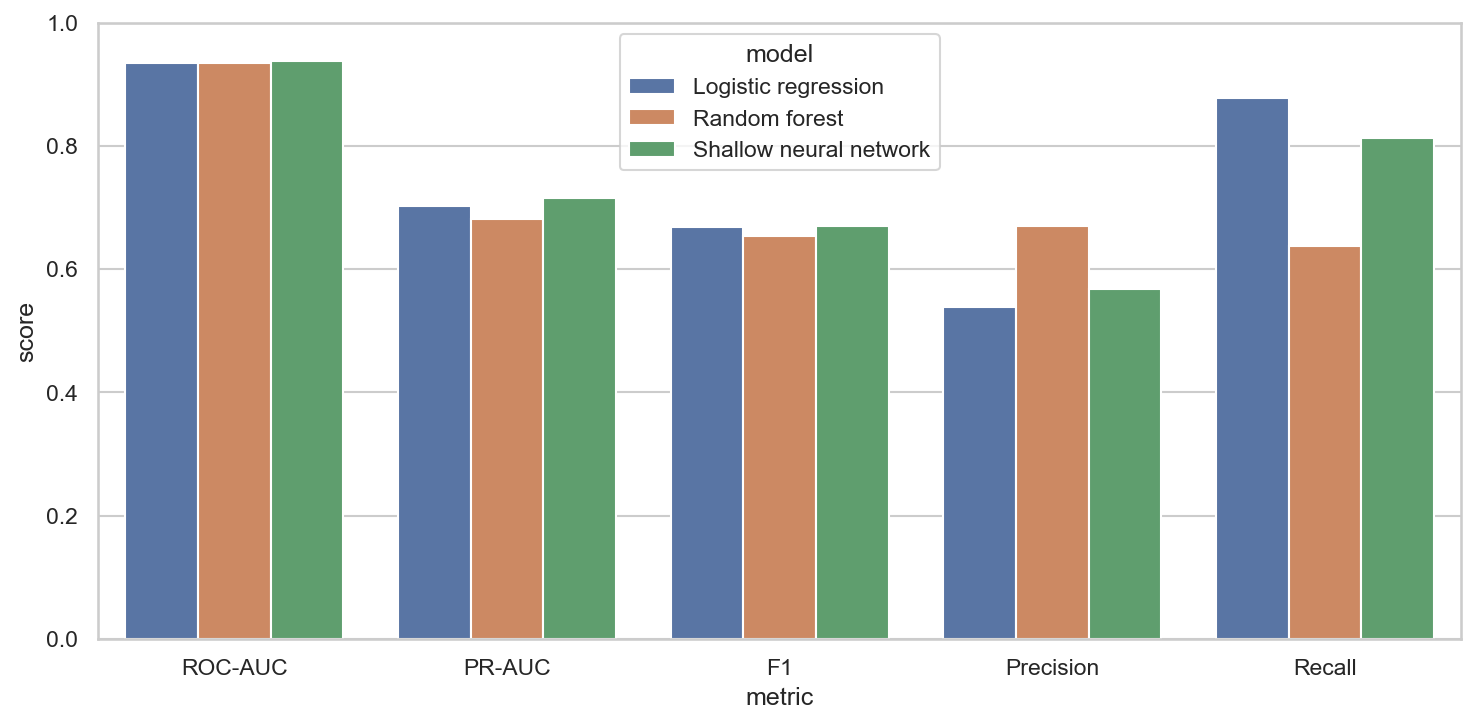

Validation-only model selection ranking:


,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
7,Shallow neural network,validation,0.240,0.928182,0.738457,0.712551,0.676923,0.752137
1,Logistic regression,validation,0.655,0.925849,0.727587,0.703125,0.647482,0.769231
4,Random forest,validation,0.635,0.922059,0.704019,0.705882,0.750000,0.666667


In [13]:
display(results["metrics"])
display(Image(filename=str(OUT / "figures" / "model_comparison.png")))
validation_ranking = (results["metrics"].query("split == 'validation'")
                      .sort_values("PR-AUC", ascending=False))
print("Validation-only model selection ranking:")
display(validation_ranking)

Logistic regression is the statistical baseline, random forest captures nonlinear interactions, and the two-hidden-layer MLP is the shallow neural network. PR-AUC is the selection metric because the positive class is uncommon. Model-specific thresholds maximize validation F1 and are frozen before test scoring. Training-to-validation differences, especially for the forest, reveal overfitting and historical distribution shift.

## 13. Feature-group ablation

,variant,features,validation_PR-AUC,validation_ROC-AUC,PR-AUC_change
0,all features,17,0.727587,0.925849,0.000000
1,without grid,13,0.701751,0.920537,-0.025837
2,without qualifying,14,0.722284,0.924186,-0.005304
3,without form,14,0.719699,0.923245,-0.007889
4,without standings,13,0.712215,0.923605,-0.015372
5,without context,14,0.723246,0.924572,-0.004342


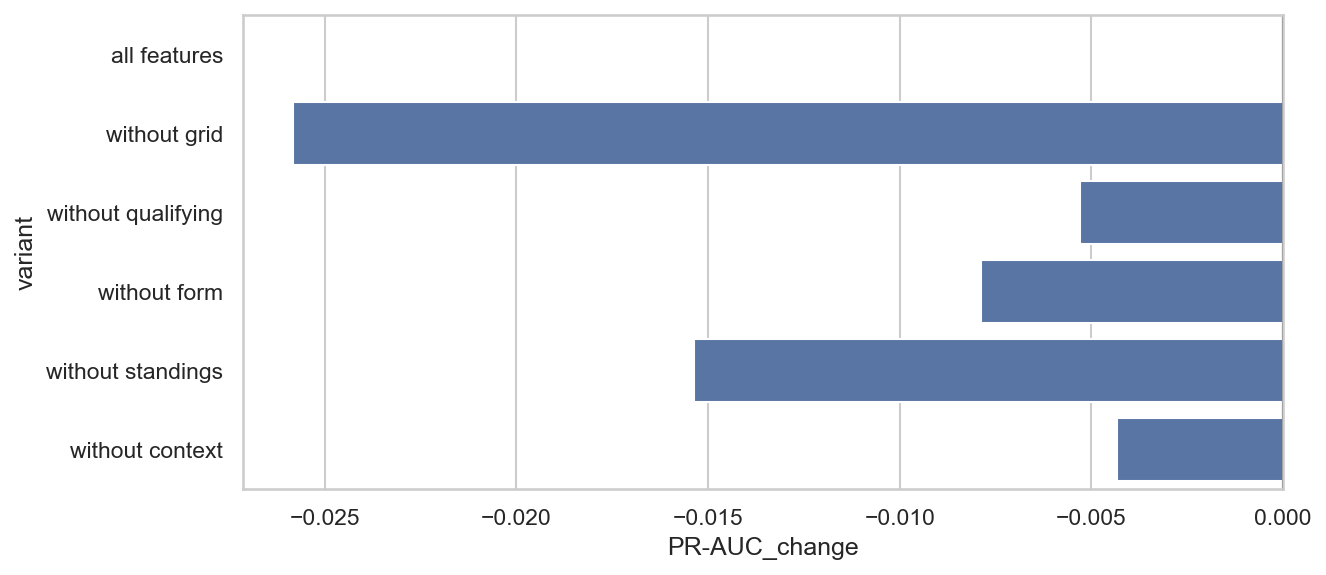

In [14]:
display(results["ablations"])
display(Image(filename=str(OUT / "figures" / "ablation.png")))

Each experiment removes one complete feature group and retrains the logistic baseline. The change from full-model validation PR-AUC measures the group's incremental predictive contribution after training and complements the earlier exploratory motivation.

## 14. Global and local explainability

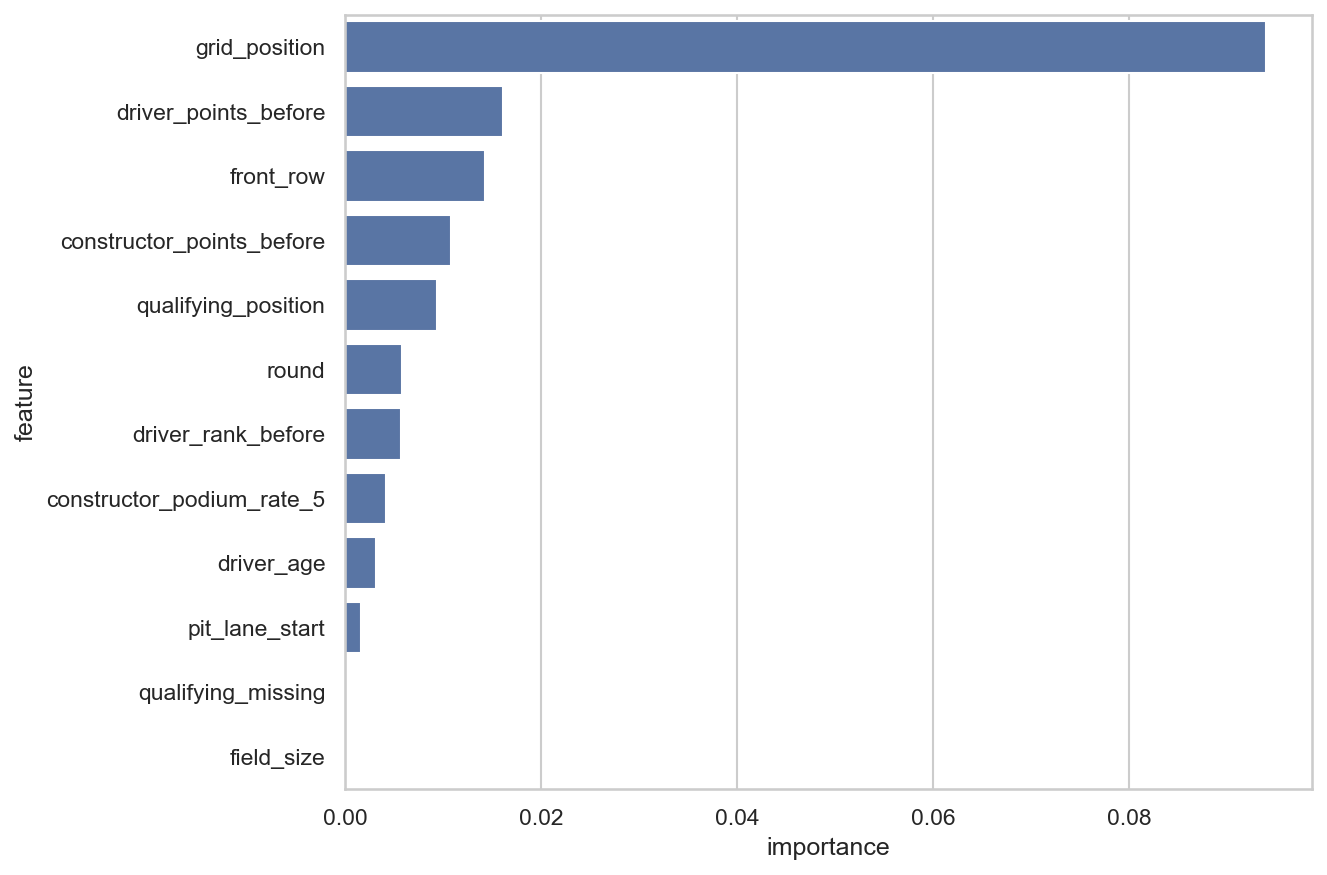

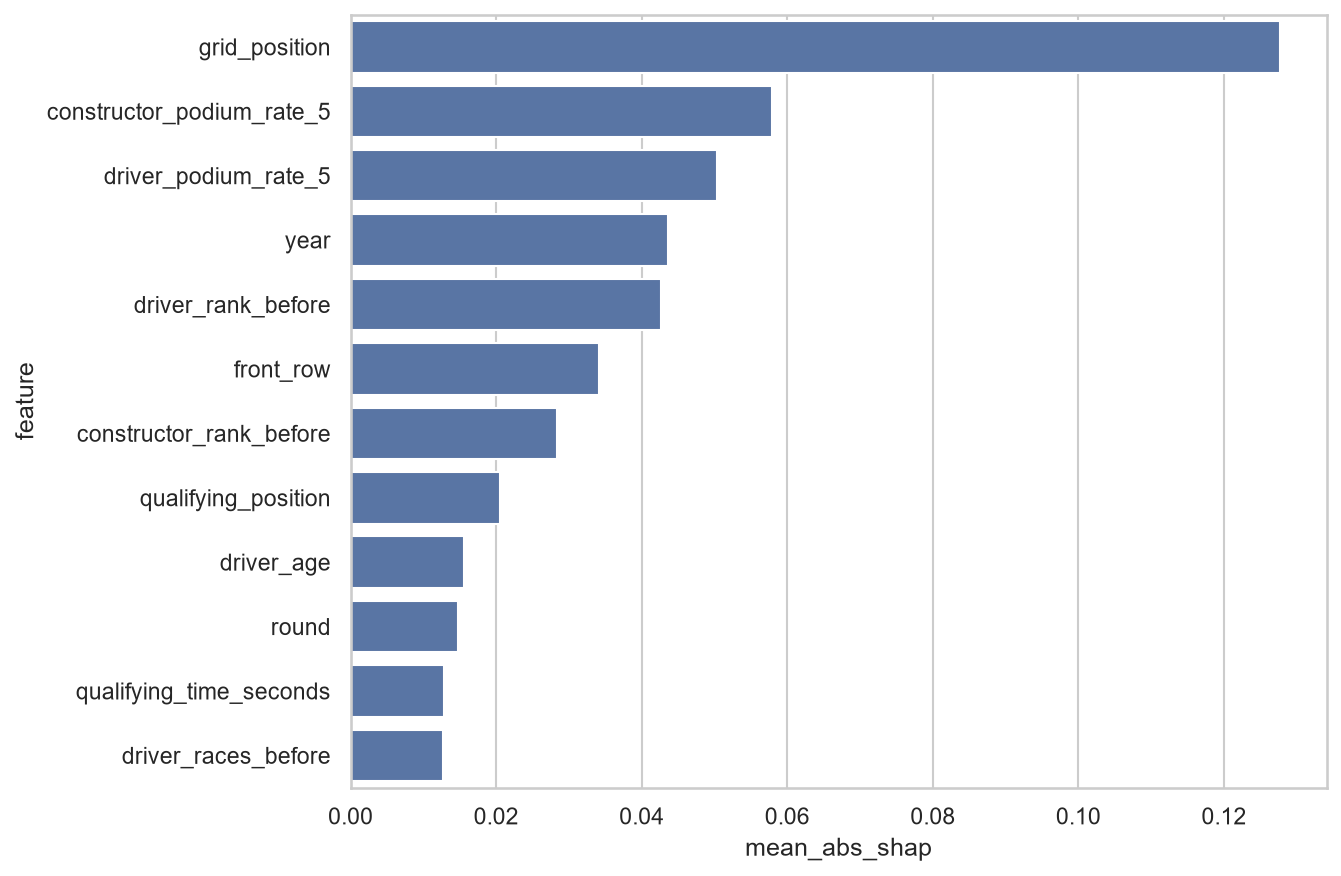

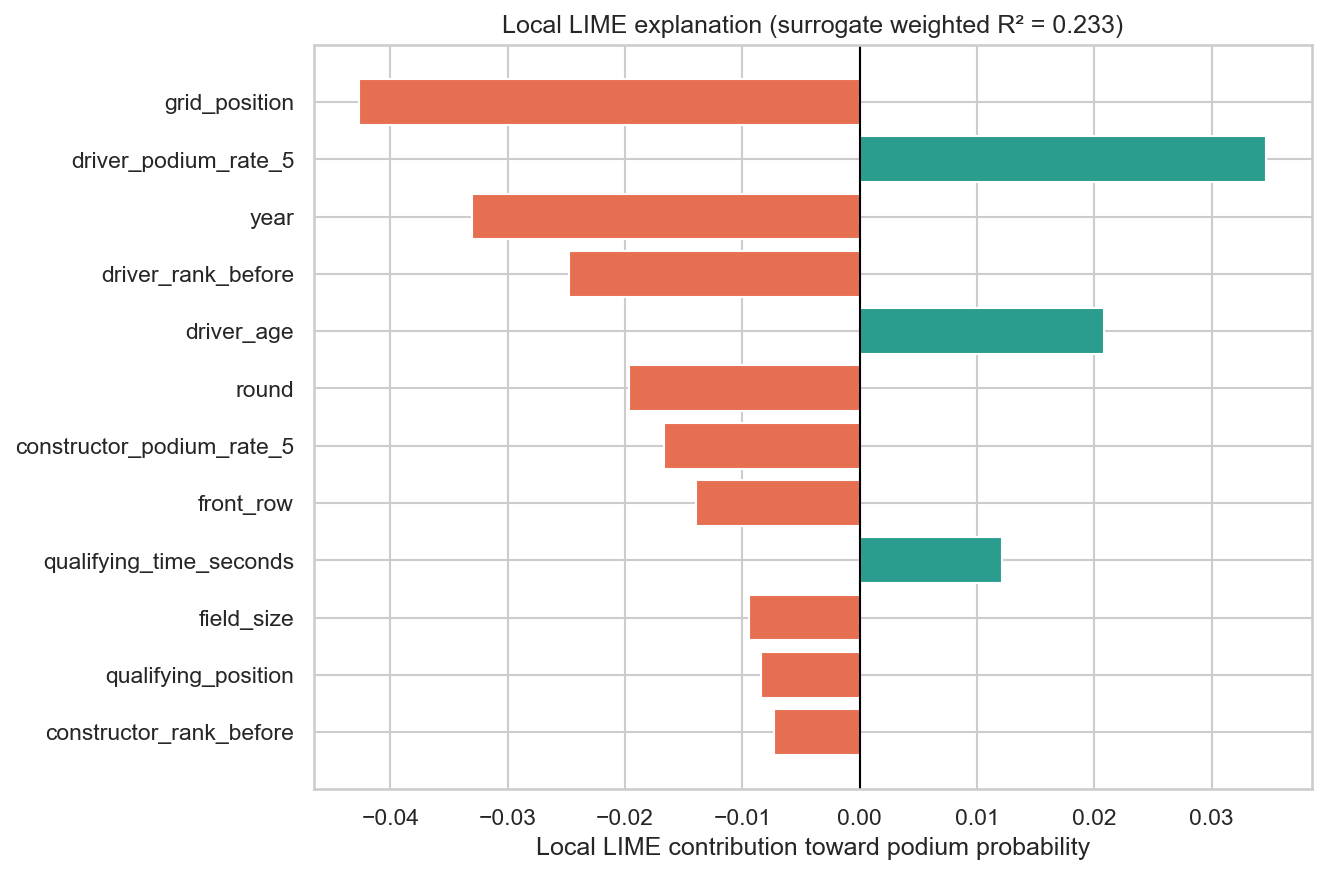

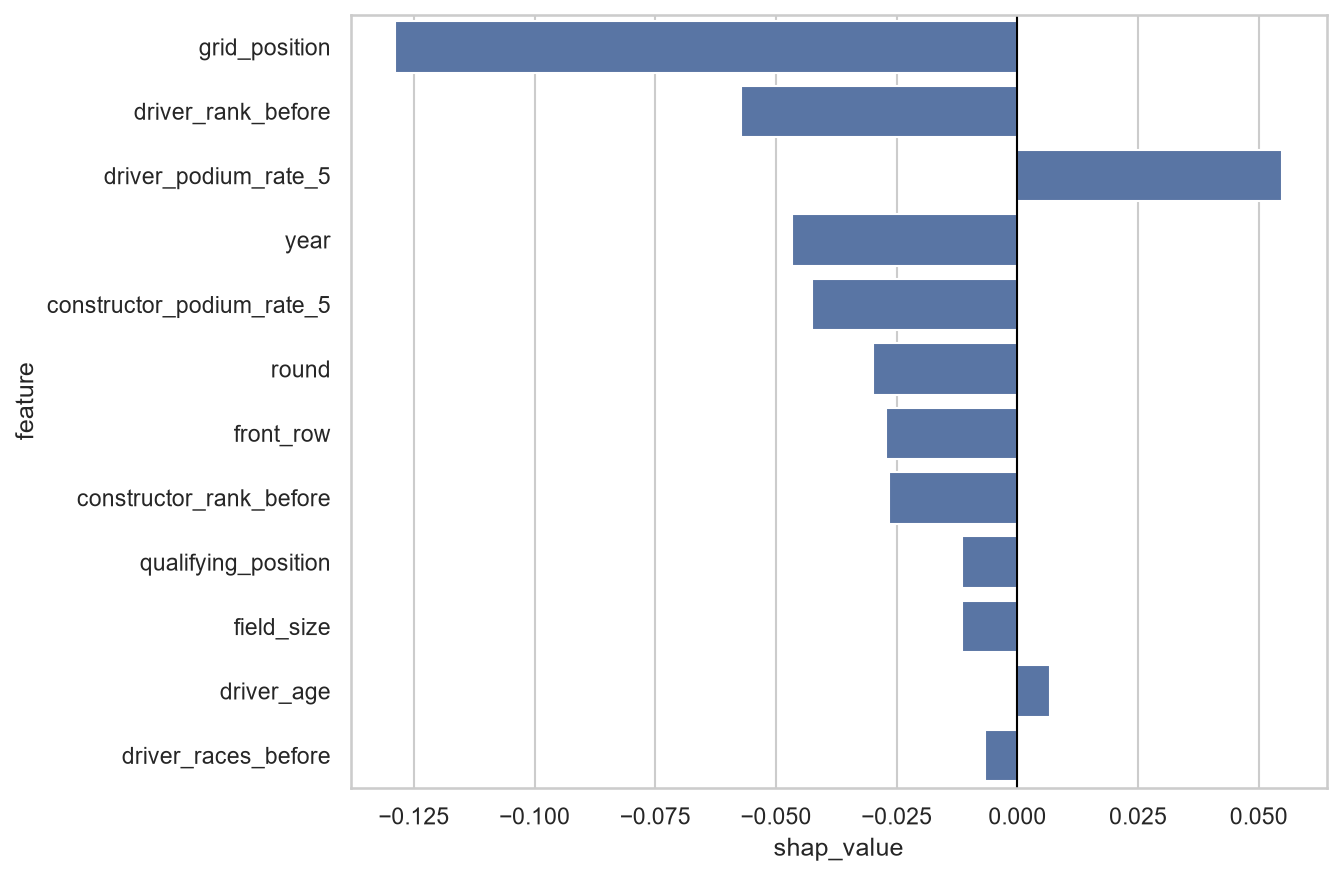

,feature,mean_abs_shap
0,grid_position,0.127701
1,constructor_podium_rate_5,0.057899
2,driver_podium_rate_5,0.050338
3,year,0.043620
4,driver_rank_before,0.042629
5,front_row,0.034164
6,constructor_rank_before,0.028380
7,qualifying_position,0.020544
8,driver_age,0.015563
9,round,0.014799


,feature,lime_weight,observed_value,model_probability,surrogate_probability,local_fidelity_r2
0,grid_position,-0.042651,11.0,0.107396,0.106946,0.233494
7,driver_podium_rate_5,0.034653,0.2,0.107396,0.106946,0.233494
16,year,-0.033014,2021,0.107396,0.106946,0.233494
11,driver_rank_before,-0.024745,15.0,0.107396,0.106946,0.233494
14,driver_age,0.020850,23.554214,0.107396,0.106946,0.233494
15,round,-0.019623,13,0.107396,0.106946,0.233494
8,constructor_podium_rate_5,-0.016718,0.1,0.107396,0.106946,0.233494
2,front_row,-0.013910,0,0.107396,0.106946,0.233494
5,qualifying_time_seconds,0.012145,70.332,0.107396,0.106946,0.233494
3,field_size,-0.009433,20,0.107396,0.106946,0.233494


,feature,shap_value,observed_value
0,grid_position,-0.128913,11.000000
1,driver_rank_before,-0.057282,15.000000
2,driver_podium_rate_5,0.054841,0.200000
3,year,-0.046582,2021.000000
4,constructor_podium_rate_5,-0.042630,0.100000
5,round,-0.030000,13.000000
6,front_row,-0.027297,0.000000
7,constructor_rank_before,-0.026648,8.000000
8,qualifying_position,-0.011446,11.000000
9,field_size,-0.011370,20.000000


In [15]:
for figure in ["permutation_importance", "shap_global", "lime_local", "shap_local"]:
    display(Image(filename=str(OUT / "figures" / f"{figure}.png")))
display(results["shap_global"].head(12))
display(results["lime_local"].head(12))
display(results["shap_local"].head(12))

Permutation importance measures the validation PR-AUC change after shuffling one feature, and global SHAP summarizes average contribution magnitude. Local LIME explains one fixed validation prediction with 5,000 perturbations around that row and a distance-weighted ridge surrogate; its weighted R² reports local fidelity. Positive LIME weights push the surrogate toward a podium and negative weights push it away. Local SHAP is retained as a supplementary cross-check. Correlated predictors can divide importance differently across methods. These values describe fitted-model reliance and are **not causal effects**.

## 15. Complete and partially missing inference

In [16]:
display(results["summary"]["inference_demos"])

{'model': 'Shallow neural network',
 'complete_record': {'podium_probability': 0.08661545099344511,
  'predicted_podium': False,
  'threshold': 0.24},
 'partial_record': {'podium_probability': 0.03189925681062999,
  'predicted_podium': False,
  'threshold': 0.24}}

The complete example follows the normal inference path. The partial example demonstrates that missing inputs are handled by the imputer fitted on training seasons, without consulting validation or test data. Its output demonstrates software robustness rather than a historical base rate.

## 16. Limitations

- Qualifying coverage is sparse and era-dependent in older seasons.
- Regulations, field size, reliability, and competitive structure change over time.
- Constructor identifiers do not necessarily bridge team renames.
- The nationality-to-country mapping is incomplete and cannot represent multiple nationalities.
- Mechanical status classification is rules-based and can miss ambiguous causes.
- Validation contains only the 2020-2021 seasons, so selection estimates have sampling uncertainty.
- Probabilities were evaluated for ranking and threshold classification, not formal calibration.
- Permutation importance, SHAP, and LIME explain associations inside fitted models, not causes of podium finishes.